In [1]:
import ROOT
import pandas as pd
import numpy as np
import os
import sys
import ipynbname
from pathlib import Path

project_root = str(ipynbname.path().parent.parent)
sys.path.append(project_root)
project_root=Path(project_root)

from processing import SiphraAcquisition, MetadataLoader
from analysis import fit_peak_expbg

# Constants
BITS12 = 2**12
BITS9 = 2**9 # 512 typical number of bins used

# Energy emission peaks in MeV
Cs137_MeV = 0.662
Na22_MeV = [0.511, 1.275, 1.786]
Co60_MeV = [1.173, 1.332, 2,505]
Am241_MeV = 0.0595
# Background emission
K40_MeV = 1.460
Tl208_MEV = 2.614

colors = [
    ROOT.kRed + 1,
    ROOT.kBlue + 1,
    ROOT.kGreen + 2,
    ROOT.kOrange + 7,
    ROOT.kMagenta + 1,
    ROOT.kCyan + 1,
    ROOT.kViolet + 2,
    ROOT.kPink + 7,
    ROOT.kTeal + 3,
    ROOT.kAzure + 2,
    ROOT.kSpring + 5,
]
siphras = ['A', 'B']

In [2]:
files = sorted((project_root/'data/260526').glob('*_SUBT_*'))
acqs = [SiphraAcquisition(file) for file in files]
print(acqs)
#print(acqs)
#Abackground = acqs[12]
#Bbackground = acqs[25]
backgrounds = [acqs[0], acqs[11]]
#calibrations = [acqs[0], acqs[13]]
Aacqs = acqs[1:11]
Bacqs = acqs[12:]
acqs = [Aacqs, Bacqs]
print(backgrounds)
#print(calibrations)
print(acqs)

[SIPHRAAcquisition(File: 'A_SUBT_01_CollimatedSource_Background'), SIPHRAAcquisition(File: 'A_SUBT_02_CollimatedSourceTest_Cs137_3cm'), SIPHRAAcquisition(File: 'A_SUBT_03_CollimatedSourceTest_Cs137_4cm'), SIPHRAAcquisition(File: 'A_SUBT_04_CollimatedSourceTest_Cs137_5cm'), SIPHRAAcquisition(File: 'A_SUBT_05_CollimatedSourceTest_Cs137_6cm'), SIPHRAAcquisition(File: 'A_SUBT_06_CollimatedSourceTest_Cs137_7cm'), SIPHRAAcquisition(File: 'A_SUBT_07_CollimatedSourceTest_Cs137_8cm'), SIPHRAAcquisition(File: 'A_SUBT_08_CollimatedSourceTest_Cs137_9cm'), SIPHRAAcquisition(File: 'A_SUBT_09_CollimatedSourceTest_Cs137_10cm'), SIPHRAAcquisition(File: 'A_SUBT_10_CollimatedSourceTest_Cs137_11cm'), SIPHRAAcquisition(File: 'A_SUBT_11_CollimatedSourceTest_Cs137_12cm'), SIPHRAAcquisition(File: 'B_SUBT_01_CollimatedSource_Background'), SIPHRAAcquisition(File: 'B_SUBT_02_CollimatedSourceTest_Cs137_3cm'), SIPHRAAcquisition(File: 'B_SUBT_03_CollimatedSourceTest_Cs137_4cm'), SIPHRAAcquisition(File: 'B_SUBT_04_C

In [3]:
# Create histograms for background and each distance for both siphras. Create background subtracted histograms. 
hists = {}
distances_cm = list(range(3, 13))
for i in range(2):
    siphra = siphras[i]
    bg = backgrounds[i]

    #Background
    hist_bg = ROOT.TH1F(f"{siphra}_Background", "", BITS12, 0 , BITS12)
    hist_bg.Fill(bg['s']/len(bg.active_chs))
    hist_bg.GetXaxis().SetTitle("ADC channel number")
    hist_bg.GetYaxis().SetTitle(r"Normalized counts")
    hists[f"{siphra}_Background"] = hist_bg
    
    for sgnl, distance in zip(acqs[i], distances_cm):

        # Distance to B = 15 - distance to A
        if siphra == 'B':
            distance = 15-distance
        print(distance)
            
        filepath = sgnl.filepath.stem

        # Signal
        hist_sgnl = ROOT.TH1F(f"{siphra}_{distance}cm_signal", "", BITS12, 0, BITS12)
        hist_sgnl.Fill(sgnl['s']/len(sgnl.active_chs))      
        hist_sgnl.Scale(bg.exposure/sgnl.exposure)
        
        # Clean spectrum
        hist_clean = hist_sgnl.Clone(f"{siphra}_{distance}cm_clean")
        hist_clean.Add(hist_bg, -1)
        
        for hist in [hist_sgnl, hist_clean]:
            hist.GetXaxis().SetTitle("ADC channel number")
            hist.GetYaxis().SetTitle(r"Normalized counts")
            
        hists[f"{siphra}_{distance}cm_signal"] = hist_sgnl      
        hists[f"{siphra}_{distance}cm_clean"] = hist_clean
        
        del hist_sgnl
        del hist_clean
    del hist_bg

3
4
5
6
7
8
9
10
11
12
12
11
10
9
8
7
6
5
4
3


In [4]:
#Draw one histogram for each distance + siphra combination

if ROOT.gROOT.FindObject('cv1'):
    ROOT.gROOT.FindObject('cv1').Close()

Yinit = 0.82 # For stat boxes

cv1 = ROOT.TCanvas('cv1', 'cv1', 4800, 2400)
cv1.Divide(3, 4)

#cv1 = ROOT.TCanvas('cv1', 'cv1', 4800, 2400)
#cv1.Divide(5, 5)

ROOT.gStyle.SetOptStat(11)
ROOT.gStyle.SetStatFontSize(0.03)
ROOT.gStyle.SetStatW(0.16)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(22)]

for i, siphra in enumerate(siphras):  
    for idx, distance in enumerate(distances_cm):
        lg = lgds[10*i + idx]
        cv1.cd(10*i+idx+1)
        cv1.cd(10*i+idx+1).SetLogy()
        
        bg = hists[f"{siphra}_Background"] 
        sgnl = hists[f"{siphra}_{distance}cm_signal"]         
        clean = hists[f"{siphra}_{distance}cm_clean"] 
        
        lg.AddEntry(sgnl, r"^{137}Cs signal")
        lg.AddEntry(bg, "Background")
        lg.AddEntry(clean, r"^{137}Cs, Background subtracted")
        
        sgnl.SetLineColor(colors[0])
        bg.SetLineColor(colors[1])
        clean.SetLineColor(colors[2])
        #sgnl.SetTitle(str(distance))
        #clean.SetTitle(f"SIPHRA {siphra} distance: {distance} cm")
        print(distance)
        sgnl.SetTitle(f"SIPHRA {siphra} distance: {distance} cm")

        # Drw histograms
        sgnl.Draw("hist")
        bg.Draw("sames hist")
        clean.Draw("sames hist")
        
        ROOT.gPad.Update()
        lg.Draw()
        cv1.Draw()
    


3
4
5
6
7
8
9
10
11
12
3
4
5
6
7
8
9
10
11
12


In [5]:
#Plot all the subtracted histogram spectra in one plot.

if ROOT.gROOT.FindObject('cv2'):
    ROOT.gROOT.FindObject('cv2').Close()

Yinit = 0.82 # For stat boxes

cv2 = ROOT.TCanvas('cv2', 'cv2', 2400, 1200)
cv2.Divide(2,1)

ROOT.gStyle.SetOptStat(11)
ROOT.gStyle.SetStatFontSize(0.03)
ROOT.gStyle.SetStatW(0.16)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(2)]

for i, (siphra, lg) in enumerate(zip(siphras, lgds)):
    cv2.cd(i+1)
    cv2.cd(i+1).SetLogy()
    

    for idx, (distance) in enumerate(distances_cm):   
        
        clean = hists[f"{siphra}_{distance}cm_clean"] 
        lg.AddEntry(clean, f"Bg subtracted {distance} cm SIPHRA {siphra}")
        clean.SetLineColor(colors[idx])
        if idx ==0:
            clean.Draw("hist")
        else:
            clean.Draw("sames hist")
        ROOT.gPad.Update()
        
    lg.Draw()   
    cv2.Draw()

260.38485133354055
261.89663983013145
261.65443628304473
258.92190934054014
260.9645590762557
260.15400737833727
262.40131370213834
259.8452620089598
258.14340568929816
255.1112805087584
290.9873931908764
289.85815801860156
288.8439766609636
286.5173757437463
287.58165601570386
285.0003949186167
288.8808409684377
287.52726467475287
288.75313285516984
289.2410456487965
[[np.float64(1.0016814332521482), np.float64(1.0074971727634283), np.float64(1.0065654334746714), np.float64(0.9960536026590532), np.float64(1.00391152643774), np.float64(1.000793393480551), np.float64(1.009438616149431), np.float64(0.999605672679882), np.float64(0.9930587561878612), np.float64(0.9813943929152358)], [np.float64(1.00925456933102), np.float64(1.0053379537520073), np.float64(1.0018203884097348), np.float64(0.9937508546029178), np.float64(0.9974421819684901), np.float64(0.9884893901368428), np.float64(1.0019482478003272), np.float64(0.9972535321827215), np.float64(1.0015053076597153), np.float64(1.00319757415

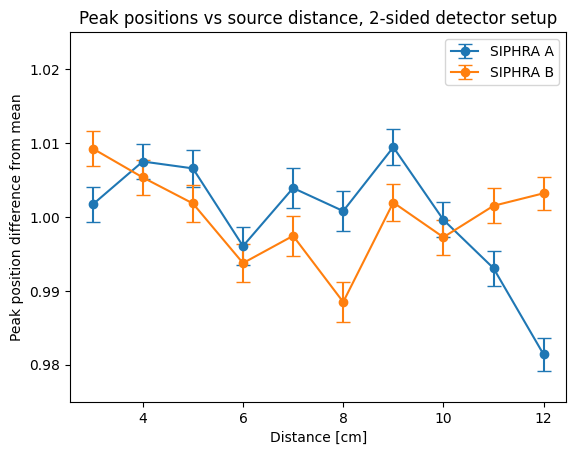

****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      284.439
NDf                       =          247
Edm                       =   7.7299e-09
NCalls                    =           69
Constant                  =      372.508   +/-   3.93938     
Mean                      =      260.385   +/-   0.541864    
Sigma                     =      47.9731   +/-   0.517862     	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      296.487
NDf                       =          247
Edm                       =  4.23966e-06
NCalls                    =           61
Constant                  =      322.289   +/-   3.81927     
Mean                      =      261.897   +/-   0.625423    
Sigma                     =      49.1703   +/-   0.611056     	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      321.333
NDf                   

In [6]:
#Plot the mean ADC value of the photopeak for each SIPHRA and distance. Include error bars.
#TODO: show as a percentage deviation from total mean? Like in Mozsis plot?

import matplotlib.pyplot as plt

means_list = []
mean_avg_list = []
error_list = []
diff_avg_list = []
for i, siphra in enumerate(siphras):
    means = []
    errors = []
    for j, distance in enumerate(distances_cm):
        hist = hists[f"{siphra}_{distance}cm_clean"] 
        gaus_fit = ROOT.TF1("gaus_fit", "gaus", 150, 400)
        hist.Fit(gaus_fit, "R+S")
        
        mean = gaus_fit.GetParameter(1)
        error = gaus_fit.GetParError(1)
        print(mean)
        means.append(mean)
        errors.append(error)
    means_list.append(means)
    mean_avg = np.mean(means)
    diff_avg = [x / mean_avg for x in means]
    diff_avg_errors = [e / mean_avg for e in errors]
    #mean_avg_list.append(mean_avg)
    error_list.append(errors)
    diff_avg_list.append(diff_avg)

print(diff_avg_list)




for i, (means, errors, siphra) in enumerate(zip(diff_avg_list, error_list, siphras)):
    plt.errorbar(
        distances_cm,
        means,
        yerr=diff_avg_errors,
        fmt='o-',        # 'o' means scatter points
        capsize=5,      # little caps on error bars
        label = f"SIPHRA {siphra}"
        #ecolor='black'
    )


plt.legend()
plt.xlabel("Distance [cm]")
plt.ylabel("Peak position difference from mean")
plt.ylim(0.975, 1.025)
plt.title("Peak positions vs source distance, 2-sided detector setup")

plt.show()
        
        